In [ ]:
import os

print(os.listdir("/content"))

['.config', 'train_idx.txt', 'results_template.json', 'test_images.npy', 'model.py', 'CV Problem Statement.docx', 'labels.csv', 'train_images.npy', 'classes.txt', 'check_format.py', 'val_idx.txt', 'sample_data']


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the label table
labels = pd.read_csv("/content/labels.csv")

# Load class names
with open("/content/classes.txt", "r") as f:
    classes = [line.strip() for line in f if line.strip()]

# Load train and validation indices
train_idx = np.loadtxt("/content/train_idx.txt", dtype=int)
val_idx = np.loadtxt("/content/val_idx.txt", dtype=int)

print("Files loaded successfully!")

Files loaded successfully!


In [ ]:
print("Dataset shape:", labels.shape)
print("\nColumn names:")
print(labels.columns.tolist())

print("\nFirst 5 rows:")
display(labels.head())

print("\nMissing values:")
print(labels.isnull().sum())

print("\nClass names:")
print(classes)

Dataset shape: (50000, 4)

Column names:
['index', 'noisy_label', 'synthetic_label', 'clean_label']

First 5 rows:


,index,noisy_label,synthetic_label,clean_label
0,0,4,6,6
1,1,9,6,9
2,2,0,9,9
3,3,5,4,4
4,4,1,1,1



Missing values:
index              0
noisy_label        0
synthetic_label    0
clean_label        0
dtype: int64

Class names:
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
train_images = np.load("/content/train_images.npy")
test_images = np.load("/content/test_images.npy")

print("Training images:", train_images.shape)
print("Training image data type:", train_images.dtype)

print("Test images:", test_images.shape)
print("Test image data type:", test_images.dtype)

print("Minimum pixel value:", train_images.min())
print("Maximum pixel value:", train_images.max())

Training images: (50000, 32, 32, 3)
Training image data type: uint8
Test images: (10000, 32, 32, 3)
Test image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


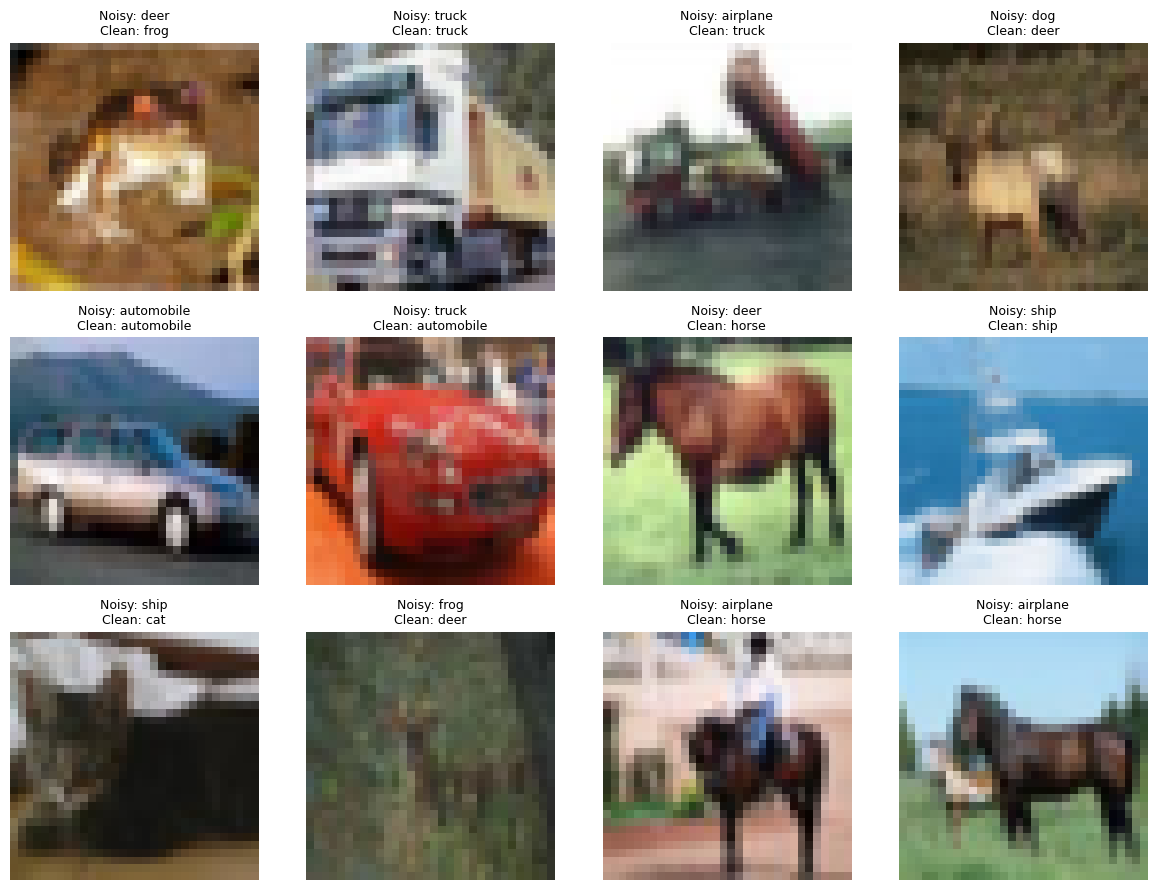

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    image_id = train_idx[i]

    # Get the image at its original index
    image = train_images[image_id]

    # Get its corresponding label row
    row = labels.loc[labels["index"] == image_id].iloc[0]

    noisy_name = classes[int(row["noisy_label"])]
    clean_name = classes[int(row["clean_label"])]

    ax.imshow(image)
    ax.set_title(
        f"Noisy: {noisy_name}\nClean: {clean_name}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Select only the 45,000 training samples
train_labels = labels.set_index("index").loc[train_idx]

# Compare human labels against clean labels
human_noise = (
    train_labels["noisy_label"] != train_labels["clean_label"]
)

# Compare synthetic labels against clean labels
synthetic_noise = (
    train_labels["synthetic_label"] != train_labels["clean_label"]
)

print(f"Training samples: {len(train_labels)}")
print(f"Human label errors: {human_noise.sum()}")
print(f"Human noise rate: {human_noise.mean():.2%}")

print(f"\nSynthetic label errors: {synthetic_noise.sum()}")
print(f"Synthetic noise rate: {synthetic_noise.mean():.2%}")

Training samples: 45000
Human label errors: 18109
Human noise rate: 40.24%

Synthetic label errors: 18044
Synthetic noise rate: 40.10%


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    train_labels["clean_label"],
    train_labels["noisy_label"],
    labels=list(range(10))
)

cm_df = pd.DataFrame(
    cm,
    index=classes,
    columns=classes
)

display(cm_df)

,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
airplane,2925,293,314,89,94,105,85,75,379,146
automobile,191,2657,63,116,80,68,60,64,71,1126
bird,263,165,2842,212,254,216,222,147,106,77
cat,180,160,354,2168,194,924,206,106,91,86
deer,184,142,316,184,2195,491,174,683,94,50
dog,150,131,240,834,183,2620,123,136,55,61
frog,170,166,373,350,229,257,2676,124,96,62
horse,179,120,111,100,233,289,101,3246,77,50
ship,369,333,94,65,96,79,71,99,3076,214
truck,180,1247,81,87,78,81,52,68,115,2486


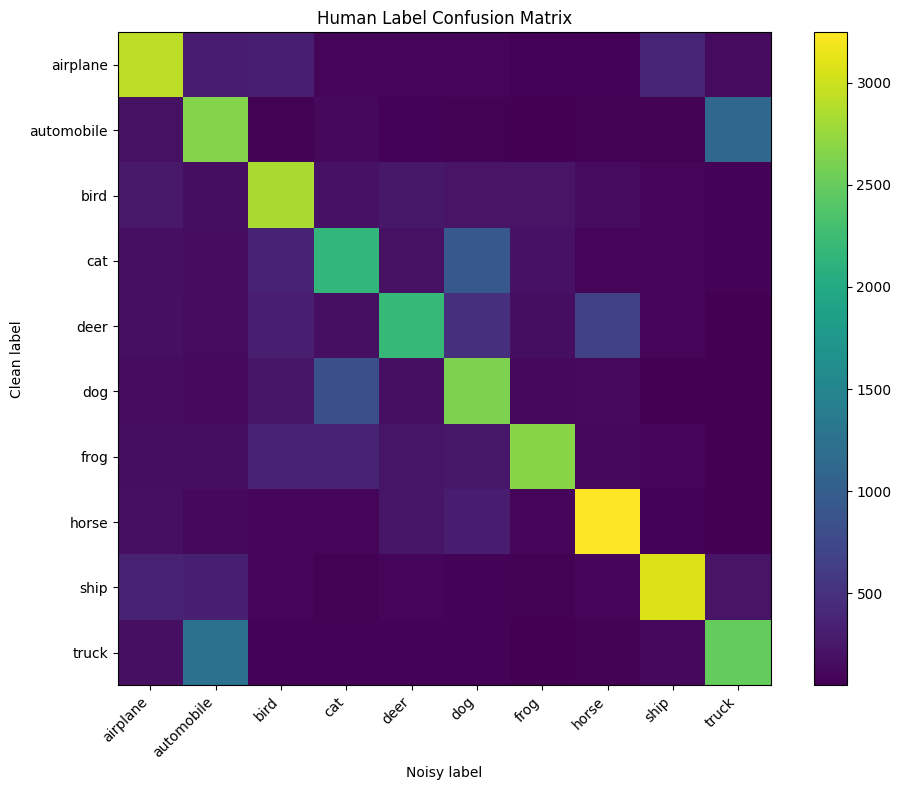

In [ ]:
plt.figure(figsize=(10, 8))

plt.imshow(cm, interpolation="nearest")
plt.colorbar()

plt.xticks(range(10), classes, rotation=45, ha="right")
plt.yticks(range(10), classes)

plt.xlabel("Noisy label")
plt.ylabel("Clean label")
plt.title("Human Label Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
# Check how many human labels are incorrect
print("Training samples:", len(train_labels))
print("Human label errors:", human_noise.sum())
print("Human noise rate:", f"{human_noise.mean():.2%}")

# Check synthetic noise
print("Synthetic label errors:", synthetic_noise.sum())
print("Synthetic noise rate:", f"{synthetic_noise.mean():.2%}")

# Show the most frequent class confusions, excluding correct labels
confusions = cm_df.copy()
import numpy as np

np.fill_diagonal(confusions.values, 0)

print("\nMost frequent class confusions:")
print(confusions.stack().sort_values(ascending=False).head(10))

Training samples: 45000
Human label errors: 18109
Human noise rate: 40.24%
Synthetic label errors: 18044
Synthetic noise rate: 40.10%

Most frequent class confusions:
truck       automobile    1247
automobile  truck         1126
cat         dog            924
dog         cat            834
deer        horse          683
            dog            491
airplane    ship           379
frog        bird           373
ship        airplane       369
cat         bird           354
dtype: int64


In [ ]:
# If model.py is uploaded directly to /content:
!sed -n '1,240p' /content/model.py

"""ResNet-18 for 32x32 CIFAR images (the standard CIFAR variant: 3x3 stem, no max-pool).

Everyone must use this exact architecture, trained from scratch (no pretrained weights).

    from model import ResNet18
    net = ResNet18(num_classes=10)

You may wrap it (e.g. two copies for co-training) but do not change the layers.
"""
import torch.nn as nn
import torch.nn.functional as F


class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes, planes, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, 1, stride=stride, bias=False),
                nn.Ba

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

x = torch.randn(1000, 1000, device=device)
y = x @ x

print("Device:", device)
print("Calculation successful!")

Device: cuda
Calculation successful!


In [ ]:
import torch
from model import ResNet18

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the model from scratch
model = ResNet18(num_classes=10).to(device)

# Test it with a batch of 32 RGB images
dummy_images = torch.randn(32, 3, 32, 32).to(device)

with torch.no_grad():
    outputs = model(dummy_images)

print("Device:", device)
print("Output shape:", outputs.shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Device: cuda
Output shape: torch.Size([32, 10])
Parameters: 11173962


In [ ]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Load files if they aren't already in memory
labels = pd.read_csv("/content/labels.csv")
train_images = np.load("/content/train_images.npy")

train_idx = np.loadtxt("/content/train_idx.txt", dtype=int)
val_idx = np.loadtxt("/content/val_idx.txt", dtype=int)


from torchvision import transforms

train_transform = transforms.Compose([
    transforms.ToPILImage(),       # NumPy array → PIL image
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()          # PIL image → PyTorch tensor
])

val_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor()
])


class CIFARNoisyDataset(Dataset):
    def __init__(self, images, indices, label_table,
                 label_column, transform=None):
        self.images = images
        self.indices = np.asarray(indices)
        self.label_table = label_table.set_index("index")
        self.label_column = label_column
        self.transform = transform

        self.targets = self.label_table.loc[
            self.indices, label_column
        ].to_numpy(dtype=np.int64)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        image_id = self.indices[position]
        image = self.images[image_id]
        label = int(self.targets[position])

        if self.transform:
            image = self.transform(image)

        return image, label

# Task 1 clean-reference training dataset
clean_train_ds = CIFARNoisyDataset(
    train_images, train_idx, labels,
    "clean_label", train_transform
)

# Task 1 noisy-baseline training dataset
noisy_train_ds = CIFARNoisyDataset(
    train_images, train_idx, labels,
    "noisy_label", train_transform
)

# Validation labels for Task 1 model selection
noisy_val_ds = CIFARNoisyDataset(
    train_images, val_idx, labels,
    "noisy_label", val_transform
)

# Build data loaders
BATCH_SIZE = 128

clean_train_loader = DataLoader(
    clean_train_ds, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)

noisy_train_loader = DataLoader(
    noisy_train_ds, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)

noisy_val_loader = DataLoader(
    noisy_val_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

# Sanity check
images, targets = next(iter(noisy_train_loader))

print("Training samples:", len(clean_train_ds))
print("Validation samples:", len(noisy_val_ds))
print("Image batch shape:", images.shape)
print("Label batch shape:", targets.shape)
print("Image range:", images.min().item(), images.max().item())

Training samples: 45000
Validation samples: 5000
Image batch shape: torch.Size([128, 3, 32, 32])
Label batch shape: torch.Size([128])
Image range: 0.0 1.0


In [ ]:
import torch
import torch.nn as nn
from model import ResNet18

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create a fresh model from scratch
model = ResNet18(num_classes=10).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

# Get one batch of noisy-labelled training images
images, targets = next(iter(noisy_train_loader))
images = images.to(device)
targets = targets.to(device)

# Forward pass
outputs = model(images)
loss = criterion(outputs, targets)

# Backpropagation and parameter update
optimizer.zero_grad()
loss.backward()
optimizer.step()

print("Device:", device)
print("Batch loss:", loss.item())
print("Output shape:", outputs.shape)
print("One training step completed successfully!")

Device: cuda
Batch loss: 2.394594430923462
Output shape: torch.Size([128, 10])
One training step completed successfully!


In [ ]:
import torch
import torch.nn as nn

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, targets in loader:
        images = images.to(device)
        targets = targets.to(device)

        # 1. Forward pass
        outputs = model(images)

        # 2. Calculate loss
        loss = criterion(outputs, targets)

        # 3. Calculate gradients
        optimizer.zero_grad()
        loss.backward()

        # 4. Update parameters
        optimizer.step()

        # Track statistics
        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        correct += (predictions == targets).sum().item()
        total += batch_size

    average_loss = total_loss / total
    accuracy = correct*100/ total

    return average_loss, accuracy

In [ ]:
from model import ResNet18

# Set up a fresh model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ResNet18(num_classes=10).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

# Train for one complete epoch using clean labels
train_loss, train_acc = train_one_epoch(
    model,
    clean_train_loader,
    criterion,
    optimizer,
    device
)

print(f"Training loss: {train_loss:.4f}")
print(f"Training accuracy: {train_acc:.2%}")

Exception in thread Thread-148 (_pin_memory_loop):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/pin_memory.py", line 52, in _pin_memory_loop
    do_one_step()
    ~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/pin_memory.py", line 28, in do_one_step
    r = in_queue.get(timeout=MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 120, in get
    return _ForkingPickler.loads(res)
           ~~~~~~~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/multiprocessing/reductions.py", line 540, in rebuild_storage_fd
    fd = df.detach()
  File "/usr/lib/python3.13/multiprocessing/resour

KeyboardInterrupt: 

In [ ]:
def evaluate_model(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            targets = targets.to(device)

            # Predict without updating model parameters
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, targets)

            batch_size = targets.size(0)
            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            correct += (predictions == targets).sum().item()
            total += batch_size

    average_loss = total_loss / total
    accuracy = correct *100/ total

    return average_loss, accuracy

In [ ]:
val_loss, val_acc = evaluate_model(
    model,
    noisy_val_loader,
    criterion,
    device
)

print(f"Validation loss (noisy labels): {val_loss:.4f}")
print(f"Validation accuracy (noisy labels): {val_acc:.2%}")

Validation loss (noisy labels): 2.8051
Validation accuracy (noisy labels): 22.32%


In [ ]:
import torch
import torch.nn as nn
from model import ResNet18

# Start a fresh model from scratch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ResNet18(num_classes=10).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

# Gradually reduce the learning rate over 60 epochs
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=60
)

history = []

for epoch in range(60):
    train_loss, train_acc = train_one_epoch(
        model, clean_train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = evaluate_model(
        model, noisy_val_loader, criterion, device
    )

    scheduler.step()

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss_noisy": val_loss,
        "val_acc_noisy": val_acc
    })

    print(
        f"Epoch {epoch + 1:02d}/60 | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc (noisy): {val_acc:.2%}"
    )

# Save the final-epoch model, as required for the Task 1 reference
torch.save(model.state_dict(), "/content/t1_clean_ref_model.pth")

# Save the training history
import pandas as pd
pd.DataFrame(history).to_csv(
    "/content/t1_clean_ref_history.csv", index=False
)

print("Training complete. Final model and history saved.")

Epoch 01/60 | Train loss: 1.8941 | Train acc: 31.17% | Val loss: 2.1613 | Val acc (noisy): 32.44%
Epoch 02/60 | Train loss: 1.4116 | Train acc: 48.03% | Val loss: 2.4134 | Val acc (noisy): 32.66%
Epoch 03/60 | Train loss: 1.1284 | Train acc: 59.57% | Val loss: 2.5251 | Val acc (noisy): 37.18%
Epoch 04/60 | Train loss: 0.9583 | Train acc: 65.87% | Val loss: 2.5594 | Val acc (noisy): 41.54%
Epoch 05/60 | Train loss: 0.8431 | Train acc: 70.07% | Val loss: 2.4844 | Val acc (noisy): 43.94%
Epoch 06/60 | Train loss: 0.7442 | Train acc: 73.97% | Val loss: 2.5217 | Val acc (noisy): 45.96%
Epoch 07/60 | Train loss: 0.6665 | Train acc: 76.72% | Val loss: 2.4739 | Val acc (noisy): 49.52%
Epoch 08/60 | Train loss: 0.6019 | Train acc: 78.91% | Val loss: 2.5250 | Val acc (noisy): 48.42%
Epoch 09/60 | Train loss: 0.5528 | Train acc: 80.78% | Val loss: 3.0696 | Val acc (noisy): 44.58%
Epoch 10/60 | Train loss: 0.5268 | Train acc: 81.93% | Val loss: 2.6391 | Val acc (noisy): 49.12%
Epoch 11/60 | Train 

In [ ]:

# TASK 1: Train the noisy-label baseline from scratch

import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd

# Use the same device as before
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 1. Create a completely fresh ResNet-18
noisy_model = ResNet18(num_classes=10).to(device)

# 2. Same loss function and optimizer as the clean reference model
criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    noisy_model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

# 3. Same learning-rate schedule
EPOCHS = 60

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# 4. Train using NOISY labels and validate using NOISY labels
noisy_history = []

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        noisy_model,
        noisy_train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate_model(
        noisy_model,
        noisy_val_loader,
        criterion,
        device
    )

    scheduler.step()

    noisy_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc_noisy": val_acc
    })

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.2f}% | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc (noisy): {val_acc:.2f}%"
    )

# 5. Save the trained model and training history
torch.save(
    noisy_model.state_dict(),
    "/content/t1_noisy_ce_model.pth"
)

pd.DataFrame(noisy_history).to_csv(
    "/content/t1_noisy_ce_history.csv",
    index=False
)

print("\nNoisy-label baseline training complete!")
print("Model saved: /content/t1_noisy_ce_model.pth")
print("History saved: /content/t1_noisy_ce_history.csv")


Device: cuda
Epoch 01/60 | Train loss: 2.2257 | Train acc: 20.30% | Val loss: 2.0236 | Val acc (noisy): 25.84%
Epoch 02/60 | Train loss: 1.9670 | Train acc: 28.51% | Val loss: 2.3484 | Val acc (noisy): 22.74%
Epoch 03/60 | Train loss: 1.8878 | Train acc: 32.68% | Val loss: 2.0863 | Val acc (noisy): 25.50%
Epoch 04/60 | Train loss: 1.8282 | Train acc: 36.00% | Val loss: 1.9102 | Val acc (noisy): 33.14%
Epoch 05/60 | Train loss: 1.7835 | Train acc: 38.37% | Val loss: 1.8107 | Val acc (noisy): 36.50%
Epoch 06/60 | Train loss: 1.7405 | Train acc: 40.44% | Val loss: 2.1199 | Val acc (noisy): 26.80%
Epoch 07/60 | Train loss: 1.7069 | Train acc: 42.33% | Val loss: 1.8994 | Val acc (noisy): 37.02%
Epoch 08/60 | Train loss: 1.6811 | Train acc: 43.64% | Val loss: 1.7328 | Val acc (noisy): 42.18%
Epoch 09/60 | Train loss: 1.6441 | Train acc: 45.64% | Val loss: 1.7475 | Val acc (noisy): 42.06%
Epoch 10/60 | Train loss: 1.6183 | Train acc: 46.83% | Val loss: 1.7211 | Val acc (noisy): 41.96%
Epoch 1

In [ ]:

# Check that the Task 2 components are available

required_objects = [
    "ResNet18",
    "train_one_epoch",
    "noisy_train_loader",
    "noisy_val_loader",
    "correct_eval_loader",
    "mislabeled_eval_loader",
    "val_clean_loader",
    "device"
]

for name in required_objects:
    print(f"{name}: {'Ready' if name in globals() else 'MISSING'}")


ResNet18: Ready
train_one_epoch: Ready
noisy_train_loader: Ready
noisy_val_loader: Ready
correct_eval_loader: Ready
mislabeled_eval_loader: Ready
val_clean_loader: Ready
device: Ready


In [ ]:

import os
import copy
import pandas as pd
import torch
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR

# Create folders to save Task 2 outputs
os.makedirs("/content/task2", exist_ok=True)
os.makedirs("/content/predictions", exist_ok=True)

# Function to calculate accuracy in percentage
def accuracy_on_loader(model, loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            targets = targets.to(device).long()

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == targets).sum().item()
            total += targets.size(0)

    return 100.0 * correct / total

# Start with a completely fresh model
model_t2 = ResNet18(num_classes=10).to(device)

criterion_t2 = torch.nn.CrossEntropyLoss()

optimizer_t2 = torch.optim.SGD(
    model_t2.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler_t2 = CosineAnnealingLR(optimizer_t2, T_max=60)

history_t2 = []
best_val_acc = -1.0
best_epoch = None
best_state = None

for epoch in range(1, 61):

    # Train using noisy labels
    train_loss, train_acc = train_one_epoch(
        model_t2,
        noisy_train_loader,
        criterion_t2,
        optimizer_t2,
        device
    )

    # Evaluate all four required metrics
    train_acc_correct = accuracy_on_loader(
        model_t2, correct_eval_loader, device
    )

    train_acc_mislabeled = accuracy_on_loader(
        model_t2, mislabeled_eval_loader, device
    )

    val_acc_noisy = accuracy_on_loader(
        model_t2, noisy_val_loader, device
    )

    val_acc_clean = accuracy_on_loader(
        model_t2, val_clean_loader, device
    )

    scheduler_t2.step()

    row = {
        "epoch": epoch,
        "train_acc_correct": train_acc_correct,
        "train_acc_mislabeled": train_acc_mislabeled,
        "val_acc_noisy": val_acc_noisy,
        "val_acc_clean": val_acc_clean
    }

    history_t2.append(row)

    # Save history after every epoch, in case Colab disconnects
    pd.DataFrame(history_t2).to_csv(
        "/content/task2/t2_dynamics.csv", index=False
    )

    # Select the best checkpoint ONLY using noisy validation accuracy
    if val_acc_noisy > best_val_acc:
        best_val_acc = val_acc_noisy
        best_epoch = epoch
        best_state = copy.deepcopy(model_t2.state_dict())

        torch.save(
            best_state,
            "/content/task2/t2_early_stop_model.pth"
        )

    print(
        f"Epoch {epoch:02d}/60 | "
        f"Train loss: {train_loss:.4f} | "
        f"Correct subset: {train_acc_correct:.2f}% | "
        f"Mislabeled subset: {train_acc_mislabeled:.2f}% | "
        f"Noisy val: {val_acc_noisy:.2f}% | "
        f"Clean val (diagnostic): {val_acc_clean:.2f}% | "
        f"Best epoch: {best_epoch}"
    )

# Save the final dynamics table
dynamics_t2 = pd.DataFrame(history_t2)
dynamics_t2.to_csv(
    "/content/predictions/t2_dynamics.csv", index=False
)

# Save early-stopping summary
early_stop_t2 = pd.DataFrame([{
    "best_epoch": best_epoch,
    "best_val_acc_noisy": best_val_acc
}])

early_stop_t2.to_csv(
    "/content/task2/t2_early_stop.csv", index=False
)

early_stop_t2.to_csv(
    "/content/predictions/t2_early_stop.csv", index=False
)

print("\nTask 2 training complete!")
print("Best epoch:", best_epoch)
print(f"Best noisy validation accuracy: {best_val_acc:.2f}%")
print("Dynamics saved to /content/task2/t2_dynamics.csv")


Epoch 01/60 | Train loss: 2.2061 | Correct subset: 26.54% | Mislabeled subset: 11.96% | Noisy val: 20.82% | Clean val (diagnostic): 25.64% | Best epoch: 1
Epoch 02/60 | Train loss: 1.9797 | Correct subset: 28.69% | Mislabeled subset: 12.45% | Noisy val: 22.58% | Clean val (diagnostic): 27.84% | Best epoch: 2
Epoch 03/60 | Train loss: 1.9059 | Correct subset: 44.00% | Mislabeled subset: 13.23% | Noisy val: 31.48% | Clean val (diagnostic): 40.76% | Best epoch: 3
Epoch 04/60 | Train loss: 1.8402 | Correct subset: 40.57% | Mislabeled subset: 13.12% | Noisy val: 29.94% | Clean val (diagnostic): 37.84% | Best epoch: 3
Epoch 05/60 | Train loss: 1.7907 | Correct subset: 25.15% | Mislabeled subset: 8.07% | Noisy val: 18.46% | Clean val (diagnostic): 22.52% | Best epoch: 3
Epoch 06/60 | Train loss: 1.7506 | Correct subset: 54.74% | Mislabeled subset: 15.88% | Noisy val: 39.08% | Clean val (diagnostic): 48.76% | Best epoch: 6
Epoch 07/60 | Train loss: 1.7163 | Correct subset: 61.46% | Mislabeled 

In [ ]:

import os
import pandas as pd

files_to_check = [
    "/content/t2_dynamics.csv",
    "/content/t2_early_stop.csv",
    "/content/t2_early_stop_model.pth",
    "/content/t2_dynamics.csv",
]

for path in files_to_check:
    print(f"{'FOUND' if os.path.exists(path) else 'MISSING'}: {path}")

# Load the training dynamics
history_path = "/content/t2_dynamics.csv"

if os.path.exists(history_path):
    dynamics = pd.read_csv(history_path)

    print("\nShape:", dynamics.shape)
    print("\nColumns:", dynamics.columns.tolist())
    print("\nFirst 5 epochs:")
    display(dynamics.head())

    print("\nLast 5 epochs:")
    display(dynamics.tail())

    print("\nBest epoch by noisy validation accuracy:")
    best_row = dynamics.loc[dynamics["val_acc_noisy"].idxmax()]
    display(best_row.to_frame().T)


FOUND: /content/t2_dynamics.csv
FOUND: /content/t2_early_stop.csv
MISSING: /content/t2_early_stop_model.pth
FOUND: /content/t2_dynamics.csv

Shape: (60, 5)

Columns: ['epoch', 'train_acc_correct', 'train_acc_mislabeled', 'val_acc_noisy', 'val_acc_clean']

First 5 epochs:


,epoch,train_acc_correct,train_acc_mislabeled,val_acc_noisy,val_acc_clean
0,1,26.536760,11.960903,20.82,25.64
1,2,28.689896,12.452372,22.58,27.84
2,3,43.996133,13.230990,31.48,40.76
3,4,40.567476,13.115026,29.94,37.84
4,5,25.149678,8.073334,18.46,22.52



Last 5 epochs:


,epoch,train_acc_correct,train_acc_mislabeled,val_acc_noisy,val_acc_clean
55,56,95.879662,58.440554,51.02,70.56
56,57,96.121379,62.957645,50.50,70.40
57,58,96.255253,65.470208,50.24,69.28
58,59,96.463501,66.894914,50.34,69.32
59,60,96.738686,67.137887,50.66,69.66



Best epoch by noisy validation accuracy:


,epoch,train_acc_correct,train_acc_mislabeled,val_acc_noisy,val_acc_clean
34,35.0,87.352646,15.058811,55.5,77.88


In [ ]:

import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Confirm that the test images are available
print("Test images shape:", test_images.shape)

# Load the best checkpoint
model_t2_best = ResNet18(num_classes=10).to(device)

checkpoint = torch.load(
    "/content/task2/t2_early_stop_model.pth",
    map_location=device,
    weights_only=True
)

model_t2_best.load_state_dict(checkpoint)
model_t2_best.eval()

# Test images have no labels
eval_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor()
])

class TestImageDataset(Dataset):
    def __init__(self, images, transform):
        self.images = images
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx]

        # Convert to uint8 if necessary
        if image.dtype != np.uint8:
            image = np.clip(image, 0, 255).astype(np.uint8)

        return self.transform(image)

test_dataset = TestImageDataset(test_images, eval_transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

predictions = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)
        outputs = model_t2_best(images)
        batch_predictions = outputs.argmax(dim=1)
        predictions.extend(batch_predictions.cpu().numpy().tolist())

# Save in the required id,pred format
output_path = "/content/predictions/t2_early_stop.csv"

submission = pd.DataFrame({
    "id": np.arange(len(predictions)),
    "pred": predictions
})

submission.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("Number of predictions:", len(submission))
print("Columns:", submission.columns.tolist())
print("Unique predicted classes:", sorted(submission["pred"].unique()))
display(submission.head())


NameError: name 'test_images' is not defined

In [ ]:
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
from torchvision import transforms
from model import ResNet18

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the saved Task 1 noisy-label model
noise_model = ResNet18(num_classes=10).to(device)

checkpoint = torch.load(
    "/content/t1_noisy_ce_model.pth",
    map_location=device,
    weights_only=True
)

noise_model.load_state_dict(checkpoint)
noise_model.eval()

print("Model loaded successfully!")
print("Device:", device)

Model loaded successfully!
Device: cuda


In [ ]:
import numpy as np
import torch
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Load the training data and original indices
train_images = np.load("/content/train_images.npy")
train_indices = np.loadtxt("/content/train_idx.txt", dtype=int)

print("Training images:", train_images.shape)
print("Training indices:", len(train_indices))

# Use the same basic preprocessing as evaluation
eval_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor()
])

class NoiseScoreDataset(Dataset):
    def __init__(self, images, indices, transform):
        self.images = images
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        idx = self.indices[position]
        image = self.images[idx]

        if image.dtype != np.uint8:
            image = np.clip(image, 0, 255).astype(np.uint8)

        return self.transform(image), int(idx)

noise_dataset = NoiseScoreDataset(
    train_images, train_indices, eval_transform
)

noise_loader = DataLoader(
    noise_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Generate model predictions and confidence scores
noise_model.eval()
all_indices = []
all_predictions = []
all_confidences = []

with torch.no_grad():
    for images, indices in noise_loader:
        images = images.to(device)
        logits = noise_model(images)
        probabilities = torch.softmax(logits, dim=1)

        confidence, predictions = probabilities.max(dim=1)

        all_indices.extend(indices.numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())
        all_confidences.extend(confidence.cpu().numpy().tolist())

print("Images processed:", len(all_indices))
print("Predictions generated successfully!")

Training images: (50000, 32, 32, 3)
Training indices: 45000
Images processed: 45000
Predictions generated successfully!


In [ ]:
# Load the provided labels
labels_df = pd.read_csv("/content/labels.csv")

# Keep only the noisy labels for the training indices
train_labels = labels_df.set_index("index").loc[all_indices]

noisy_labels = train_labels["noisy_label"].to_numpy()

# Model predictions and confidence from Step 2
predictions = np.array(all_predictions)
confidence = np.array(all_confidences)

# Disagreement indicator: 1 if prediction differs from provided label
disagreement = (predictions != noisy_labels).astype(float)

# Noise score: disagreement weighted by model confidence
noise_scores = disagreement * confidence

# Create the required output file
t3_scores = pd.DataFrame({
    "index": all_indices,
    "score": noise_scores
})

t3_scores = t3_scores.sort_values("index").reset_index(drop=True)
t3_scores.to_csv("/content/t3_noise_scores.csv", index=False)

print("Saved: /content/t3_noise_scores.csv")
print("Rows:", len(t3_scores))
print("Columns:", t3_scores.columns.tolist())
print("\nFirst 10 rows:")
display(t3_scores.head(10))

print("\nScore summary:")
display(t3_scores["score"].describe())

Saved: /content/t3_noise_scores.csv
Rows: 45000
Columns: ['index', 'score']

First 10 rows:


,index,score
0,0,0.775468
1,1,0.000000
2,2,0.000000
3,3,0.000000
4,4,0.000000
5,5,0.000000
6,7,0.905210
7,8,0.000000
8,9,0.000000
9,10,0.000000



Score summary:


,score
count,45000.000000
mean,0.088998
std,0.219163
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,0.996430


In [ ]:
import numpy as np
import pandas as pd

labels_df = pd.read_csv("/content/labels.csv")
train_labels = labels_df.set_index("index").loc[all_indices]

noisy_labels = train_labels["noisy_label"].to_numpy()
predictions = np.array(all_predictions)

disagreement = predictions != noisy_labels

print("Total training examples:", len(disagreement))
print("Model-label disagreements:", disagreement.sum())
print("Agreement rate:", round((~disagreement).mean() * 100, 2), "%")
print("Disagreement rate:", round(disagreement.mean() * 100, 2), "%")
print("Nonzero noise scores:", (t3_scores["score"] > 0).sum())

Total training examples: 45000
Model-label disagreements: 7026
Agreement rate: 84.39 %
Disagreement rate: 15.61 %
Nonzero noise scores: 7026


In [ ]:
import pandas as pd
import numpy as np

labels_df = pd.read_csv("/content/labels.csv").set_index("index")

# Diagnostic only: do not use these labels to train or alter the scores
diagnostic = t3_scores.set_index("index").copy()
diagnostic["noisy_label"] = labels_df.loc[
    diagnostic.index, "noisy_label"
]
diagnostic["clean_label"] = labels_df.loc[
    diagnostic.index, "clean_label"
]

diagnostic["actually_mislabeled"] = (
    diagnostic["noisy_label"] != diagnostic["clean_label"]
)

print("Examples with nonzero score:",
      (diagnostic["score"] > 0).sum())

print("\nMean score for actually mislabeled examples:")
print(diagnostic.loc[
    diagnostic["actually_mislabeled"], "score"
].mean())

print("\nMean score for correctly labeled examples:")
print(diagnostic.loc[
    ~diagnostic["actually_mislabeled"], "score"
].mean())

Examples with nonzero score: 7026

Mean score for actually mislabeled examples:
0.1966253856405903

Mean score for correctly labeled examples:
0.016518629074699576


In [ ]:
from sklearn.metrics import roc_auc_score

# Diagnostic evaluation only; do not alter the scores
y_true = diagnostic["actually_mislabeled"].astype(int).to_numpy()
y_score = diagnostic["score"].to_numpy()

auc = roc_auc_score(y_true, y_score)

top_n = int(0.10 * len(diagnostic))
top_indices = np.argsort(y_score)[-top_n:]
top10_precision = y_true[top_indices].mean()

overall_noise_rate = y_true.mean()

print(f"Overall label-noise rate: {overall_noise_rate:.2%}")
print(f"Noise-score ROC-AUC: {auc:.4f}")
print(f"Top 10% precision: {top10_precision:.2%}")
print(f"Top 10% lift: {top10_precision / overall_noise_rate:.2f}x")

Overall label-noise rate: 40.24%
Noise-score ROC-AUC: 0.6565
Top 10% precision: 89.00%
Top 10% lift: 2.21x


In [ ]:
import pandas as pd

labels_df = pd.read_csv("/content/labels.csv")

print("Columns:", labels_df.columns.tolist())
print(labels_df.head())

Columns: ['index', 'noisy_label', 'synthetic_label', 'clean_label']
   index  noisy_label  synthetic_label  clean_label
0      0            4                6            6
1      1            9                6            9
2      2            0                9            9
3      3            5                4            4
4      4            1                1            1


In [ ]:
labels_df = pd.read_csv("/content/labels.csv")

# Ensure the original image index is a column
if "index" not in labels_df.columns:
    labels_df = labels_df.reset_index()

# Use original image indices to look up noisy labels
labels_lookup = labels_df.set_index("index")["noisy_label"]

noise_model.eval()

improved_indices = []
improved_scores = []

with torch.no_grad():
    for images, indices in noise_loader:
        images = images.to(device)
        logits = noise_model(images)
        probabilities = torch.softmax(logits, dim=1)

        batch_indices = indices.numpy()
        batch_labels = labels_lookup.loc[batch_indices].to_numpy()

        batch_labels_tensor = torch.as_tensor(
            batch_labels, dtype=torch.long, device=device
        )

        label_probabilities = probabilities.gather(
            1, batch_labels_tensor.unsqueeze(1)
        ).squeeze(1)

        batch_scores = 1.0 - label_probabilities

        improved_indices.extend(batch_indices.tolist())
        improved_scores.extend(batch_scores.cpu().numpy().tolist())

improved_t3 = pd.DataFrame({
    "index": improved_indices,
    "score": improved_scores
}).sort_values("index").reset_index(drop=True)

improved_t3.to_csv(
    "/content/t3_noise_scores_improved.csv", index=False
)

print("Saved successfully!")
print("Rows:", len(improved_t3))
print("Columns:", improved_t3.columns.tolist())
print(improved_t3.head())

Saved successfully!
Rows: 45000
Columns: ['index', 'score']
   index     score
0      0  0.982693
1      1  0.502144
2      2  0.042319
3      3  0.626109
4      4  0.106917


In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

# Diagnostic evaluation only — clean labels are NOT used to create scores
labels_eval = pd.read_csv("/content/labels.csv").set_index("index")

indices = improved_t3["index"].to_numpy()

noisy = labels_eval.loc[indices, "noisy_label"].to_numpy()
clean = labels_eval.loc[indices, "clean_label"].to_numpy()
y_true = (noisy != clean).astype(int)

old_scores = (
    t3_scores.set_index("index")
    .loc[indices, "score"].to_numpy()
)
new_scores = improved_t3["score"].to_numpy()

def evaluate_scores(y_true, scores):
    auc = roc_auc_score(y_true, scores)

    n_top = int(0.10 * len(scores))
    top_idx = np.argsort(scores)[-n_top:]
    precision = y_true[top_idx].mean()

    return auc, precision

old_auc, old_precision = evaluate_scores(y_true, old_scores)
new_auc, new_precision = evaluate_scores(y_true, new_scores)

print("Method                    ROC-AUC    Top-10% precision")
print(f"Disagreement baseline     {old_auc:.4f}       {old_precision:.2%}")
print(f"Noisy-label probability   {new_auc:.4f}       {new_precision:.2%}")

Method                    ROC-AUC    Top-10% precision
Disagreement baseline     0.6565       89.00%
Noisy-label probability   0.7596       94.33%


In [ ]:
import pandas as pd
import numpy as np

# Save improved scores to the required submission path
final_t3 = improved_t3[["index", "score"]].copy()
final_t3.to_csv("/content/t3_noise_scores.csv", index=False)

# Validate the file
check = pd.read_csv("/content/t3_noise_scores.csv")
train_indices = np.loadtxt("/content/train_idx.txt", dtype=int)

print("Rows:", len(check))
print("Columns:", check.columns.tolist())
print("Every training index included exactly once:",
      len(check) == len(train_indices)
      and check["index"].nunique() == len(train_indices)
      and set(check["index"]) == set(train_indices))
print("Scores finite:", np.isfinite(check["score"]).all())
print("Scores between 0 and 1:",
      check["score"].between(0, 1).all())
print("Saved: /content/t3_noise_scores.csv")

Rows: 45000
Columns: ['index', 'score']
Every training index included exactly once: True
Scores finite: True
Scores between 0 and 1: True
Saved: /content/t3_noise_scores.csv


Actual Task 3 (My Own Logic)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# INTER-IIT CV BOOTCAMP — TASK 3: EPOCH-WISE NOISE SCORE STUDY
# Fresh ResNet-18 | 60 epochs | Per-epoch CSVs | Drive resume
# ============================================================

import os
import sys
import time
import random
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# -------------------- 1. GOOGLE DRIVE --------------------

from google.colab import drive, files

drive.mount("/content/drive")

# Required input files
REQUIRED_FILES = [
    "model.py",
    "train_images.npy",
    "labels.csv",
    "train_idx.txt",
    "val_idx.txt",
]

# If files are already in /content, this cell uses them.
# Otherwise, upload the missing files when prompted.
missing = [
    f for f in REQUIRED_FILES
    if not os.path.exists(f"/content/{f}")
]

if missing:
    print("Please upload these missing files:", missing)
    uploaded = files.upload()

    still_missing = [
        f for f in REQUIRED_FILES
        if not os.path.exists(f"/content/{f}")
    ]

    if still_missing:
        raise FileNotFoundError(
            "Missing files after upload: " + ", ".join(still_missing)
        )

# Persistent experiment directory on Google Drive
ROOT = Path("/content/drive/MyDrive/InterIIT_CV/Task3")
DATA_DIR = ROOT / "data"
CHECKPOINT_DIR = ROOT / "checkpoints"
SCORES_DIR = ROOT / "epoch_scores"

for folder in [DATA_DIR, CHECKPOINT_DIR, SCORES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Keep a copy of input files on Drive
for filename in REQUIRED_FILES:
    destination = DATA_DIR / filename
    if not destination.exists():
        shutil.copy2(f"/content/{filename}", destination)

# Import the exact supplied model.py architecture
if str(DATA_DIR) not in sys.path:
    sys.path.insert(0, str(DATA_DIR))

from model import ResNet18

# -------------------- 2. SETTINGS --------------------

SEED = 42
NUM_CLASSES = 10
EPOCHS = 60
BATCH_SIZE = 128
NUM_WORKERS = 2

LEARNING_RATE = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

# -------------------- 3. LOAD AND VALIDATE DATA --------------------

images = np.load(DATA_DIR / "train_images.npy")
labels_df = pd.read_csv(DATA_DIR / "labels.csv")

train_idx = np.loadtxt(
    DATA_DIR / "train_idx.txt", dtype=np.int64
).reshape(-1)

val_idx = np.loadtxt(
    DATA_DIR / "val_idx.txt", dtype=np.int64
).reshape(-1)

required_label_columns = {"index", "noisy_label"}
if not required_label_columns.issubset(labels_df.columns):
    raise ValueError(
        f"labels.csv must contain {required_label_columns}"
    )

if images.ndim != 4 or images.shape[1:] != (32, 32, 3):
    raise ValueError(f"Unexpected image shape: {images.shape}")

if images.dtype != np.uint8:
    raise ValueError(
        f"Expected uint8 images, got {images.dtype}"
    )

if len(train_idx) != 45000:
    raise ValueError(f"Expected 45000 train indices, got {len(train_idx)}")

if len(val_idx) != 5000:
    raise ValueError(f"Expected 5000 validation indices, got {len(val_idx)}")

if len(np.unique(train_idx)) != len(train_idx):
    raise ValueError("Duplicate indices found in train_idx.txt")

if len(np.unique(val_idx)) != len(val_idx):
    raise ValueError("Duplicate indices found in val_idx.txt")

if set(train_idx).intersection(set(val_idx)):
    raise ValueError("Training and validation indices overlap")

labels_df = labels_df.sort_values("index").reset_index(drop=True)

if labels_df["index"].duplicated().any():
    raise ValueError("Duplicate index found in labels.csv")

noisy_label_map = dict(
    zip(
        labels_df["index"].astype(int),
        labels_df["noisy_label"].astype(int)
    )
)

all_indices = set(range(len(images)))

if not set(train_idx).issubset(all_indices):
    raise ValueError("Some training indices are outside the image array")

if not set(val_idx).issubset(all_indices):
    raise ValueError("Some validation indices are outside the image array")

if not set(train_idx).issubset(noisy_label_map):
    raise ValueError("Some training indices have no noisy label")

if not set(val_idx).issubset(noisy_label_map):
    raise ValueError("Some validation indices have no noisy label")

if not labels_df["noisy_label"].between(0, 9).all():
    raise ValueError("Noisy labels must be between 0 and 9")

print("Images:", images.shape)
print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))

# -------------------- 4. TRANSFORMS AND DATASETS --------------------

# Augmentation is used only during training.
train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

# No random augmentation during scoring or validation.
eval_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
])

class CIFARSubset(Dataset):
    def __init__(self, image_array, indices, label_map, transform):
        self.image_array = image_array
        self.indices = np.asarray(indices, dtype=np.int64)
        self.label_map = label_map
        self.transform = transform

        self.labels = np.asarray(
            [self.label_map[int(i)] for i in self.indices],
            dtype=np.int64
        )

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        original_index = int(self.indices[position])
        image = self.image_array[original_index]
        label = int(self.label_map[original_index])

        image = self.transform(image)

        return image, label, original_index

train_dataset = CIFARSubset(
    images, train_idx, noisy_label_map, train_transform
)

# Same training images and labels, but deterministic preprocessing.
score_dataset = CIFARSubset(
    images, train_idx, noisy_label_map, eval_transform
)

val_dataset = CIFARSubset(
    images, val_idx, noisy_label_map, eval_transform
)

# Separate generator makes the shuffled training order reproducible.
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    generator=loader_generator,
    persistent_workers=(NUM_WORKERS > 0),
)

score_loader = DataLoader(
    score_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

# -------------------- 5. MODEL, OPTIMIZER, SCHEDULER --------------------

model = ResNet18(num_classes=NUM_CLASSES).to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
)

# Resume state only advances after the epoch checkpoint AND CSV are saved.
RESUME_PATH = ROOT / "latest_completed_state.pth"
HISTORY_PATH = ROOT / "t3_epoch_history.csv"

history = []
completed_epoch = 0

def save_torch_atomic(obj, destination):
    destination = Path(destination)
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    torch.save(obj, temporary)
    os.replace(temporary, destination)

def save_csv_atomic(df, destination):
    destination = Path(destination)
    temporary = destination.with_suffix(".csv.tmp")
    df.to_csv(temporary, index=False)
    os.replace(temporary, destination)

def make_state(epoch):
    return {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "history": history,
        "python_rng_state": random.getstate(),
        "numpy_rng_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available() else None
        ),
        "loader_generator_state": loader_generator.get_state(),
    }

def restore_state(state):
    global history, completed_epoch

    model.load_state_dict(state["model_state_dict"])
    optimizer.load_state_dict(state["optimizer_state_dict"])
    scheduler.load_state_dict(state["scheduler_state_dict"])

    history = state.get("history", [])
    completed_epoch = int(state["epoch"])

    random.setstate(state["python_rng_state"])
    np.random.set_state(state["numpy_rng_state"])
    torch.set_rng_state(state["torch_rng_state"])

    if torch.cuda.is_available() and state.get("cuda_rng_state") is not None:
        torch.cuda.set_rng_state_all(state["cuda_rng_state"])

    if "loader_generator_state" in state:
        loader_generator.set_state(state["loader_generator_state"])

# -------------------- 6. PER-EPOCH SCORE CSV --------------------

EXPECTED_COLUMNS = [
    "index",
    "noisy_label",
    "predicted_label",
    "probability_noisy_label",
    "probability_predicted_label",
    *[f"probability_class_{c}" for c in range(10)],
    "cross_entropy_loss",
]

@torch.no_grad()
def export_epoch_scores(epoch):
    """
    Score every training image with the current epoch's model.
    No random augmentation is applied during scoring.
    """
    model.eval()

    all_indices_out = []
    all_labels_out = []
    all_probs_out = []
    all_preds_out = []
    all_losses_out = []

    for batch_images, batch_labels, batch_indices in score_loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        batch_labels = batch_labels.to(DEVICE, non_blocking=True)

        logits = model(batch_images)

        # Softmax probabilities for all 10 classes.
        probabilities = torch.softmax(logits, dim=1)

        # Per-image CE against the provided noisy label.
        losses = F.cross_entropy(
            logits, batch_labels, reduction="none"
        )

        predicted_labels = probabilities.argmax(dim=1)
        probability_noisy_label = probabilities.gather(
            1, batch_labels.unsqueeze(1)
        ).squeeze(1)

        probability_predicted_label = probabilities.max(dim=1).values

        all_indices_out.append(batch_indices.numpy())
        all_labels_out.append(batch_labels.cpu().numpy())
        all_probs_out.append(probabilities.cpu().numpy())
        all_preds_out.append(predicted_labels.cpu().numpy())
        all_losses_out.append(losses.cpu().numpy())

    indices_out = np.concatenate(all_indices_out)
    labels_out = np.concatenate(all_labels_out)
    probs_out = np.concatenate(all_probs_out)
    preds_out = np.concatenate(all_preds_out)
    losses_out = np.concatenate(all_losses_out)

    # Guarantee each row corresponds to its original dataset index.
    order = np.argsort(indices_out)
    indices_out = indices_out[order]
    labels_out = labels_out[order]
    probs_out = probs_out[order]
    preds_out = preds_out[order]
    losses_out = losses_out[order]

    if len(indices_out) != 45000:
        raise RuntimeError(
            f"Epoch {epoch}: expected 45000 rows, got {len(indices_out)}"
        )

    if len(np.unique(indices_out)) != 45000:
        raise RuntimeError(
            f"Epoch {epoch}: duplicate or missing training indices"
        )

    probability_noisy_label = probs_out[
        np.arange(len(labels_out)), labels_out
    ]

    probability_predicted_label = probs_out.max(axis=1)

    output = {
        "index": indices_out.astype(np.int64),
        "noisy_label": labels_out.astype(np.int64),
        "predicted_label": preds_out.astype(np.int64),
        "probability_noisy_label": probability_noisy_label,
        "probability_predicted_label": probability_predicted_label,
    }

    for class_id in range(NUM_CLASSES):
        output[f"probability_class_{class_id}"] = probs_out[:, class_id]

    output["cross_entropy_loss"] = losses_out

    score_df = pd.DataFrame(output, columns=EXPECTED_COLUMNS)

    csv_path = SCORES_DIR / f"epoch_{epoch}.csv"
    save_csv_atomic(score_df, csv_path)

    # Verify the saved file schema and row count.
    if list(score_df.columns) != EXPECTED_COLUMNS or len(score_df) != 45000:
        raise RuntimeError(f"Epoch {epoch}: score CSV validation failed")

    print(
        f"Saved {csv_path.name}: {len(score_df):,} rows, "
        f"{len(score_df.columns)} columns"
    )

    return {
        "mean_train_score_loss": float(losses_out.mean()),
        "mean_probability_noisy_label": float(probability_noisy_label.mean()),
        "prediction_disagreement_rate": float(
            np.mean(preds_out != labels_out)
        ),
    }

# -------------------- 7. VALIDATION AND TRAINING --------------------

@torch.no_grad()
def evaluate_noisy_validation():
    model.eval()
    correct = 0
    total = 0
    loss_sum = 0.0

    for batch_images, batch_labels, _ in val_loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        batch_labels = batch_labels.to(DEVICE, non_blocking=True)

        logits = model(batch_images)
        loss_sum += F.cross_entropy(
            logits, batch_labels, reduction="sum"
        ).item()

        correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        total += batch_labels.size(0)

    return 100.0 * correct / total, loss_sum / total

def train_one_epoch(epoch):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels, _ in train_loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        batch_labels = batch_labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(batch_images)
        loss = criterion(logits, batch_labels)

        loss.backward()
        optimizer.step()

        batch_size = batch_labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        total += batch_size

    return running_loss / total, 100.0 * correct / total

# -------------------- 8. RESUME IF POSSIBLE --------------------

if RESUME_PATH.exists():
    print("Found a previous completed state. Resuming...")
    resume_state = torch.load(
        RESUME_PATH, map_location=DEVICE, weights_only=False
    )
    restore_state(resume_state)
    print("Last fully completed epoch:", completed_epoch)
else:
    print("No previous completed state. Starting from epoch 1.")

# Recovery case: checkpoint was saved, but its CSV/state update was interrupted.
# Recover the next epoch from its checkpoint if the CSV is missing.
next_epoch = completed_epoch + 1
next_ckpt_path = CHECKPOINT_DIR / f"epoch_{next_epoch}.pth"
next_csv_path = SCORES_DIR / f"epoch_{next_epoch}.csv"

if next_epoch <= EPOCHS and next_ckpt_path.exists() and not next_csv_path.exists():
    print(
        f"Recovering epoch {next_epoch}: checkpoint exists but CSV is missing."
    )

    recovery_state = torch.load(
        next_ckpt_path, map_location=DEVICE, weights_only=False
    )
    restore_state(recovery_state)

    score_metrics = export_epoch_scores(next_epoch)

    # Add recovery diagnostics to the history if not already present.
    if not any(int(row["epoch"]) == next_epoch for row in history):
        history.append({
            "epoch": next_epoch,
            "train_loss": np.nan,
            "train_accuracy_noisy": np.nan,
            "val_loss_noisy": np.nan,
            "val_accuracy_noisy": np.nan,
            **score_metrics,
            "learning_rate_next_epoch": optimizer.param_groups[0]["lr"],
        })

    history = sorted(history, key=lambda row: int(row["epoch"]))
    save_csv_atomic(pd.DataFrame(history), HISTORY_PATH)
    save_torch_atomic(make_state(next_epoch), RESUME_PATH)
    completed_epoch = next_epoch

# -------------------- 9. MAIN 60-EPOCH LOOP --------------------

for epoch in range(completed_epoch + 1, EPOCHS + 1):
    start_time = time.time()

    train_loss, train_acc = train_one_epoch(epoch)
    val_acc, val_loss = evaluate_noisy_validation()

    # Step scheduler once after this epoch's training/validation.
    scheduler.step()
    next_lr = optimizer.param_groups[0]["lr"]

    # Save an epoch checkpoint BEFORE scoring, so a missing CSV can be recovered.
    checkpoint_path = CHECKPOINT_DIR / f"epoch_{epoch}.pth"
    epoch_state = make_state(epoch)
    save_torch_atomic(epoch_state, checkpoint_path)

    # Required: score all 45k images after this epoch and save the CSV.
    score_metrics = export_epoch_scores(epoch)

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy_noisy": train_acc,
        "val_loss_noisy": val_loss,
        "val_accuracy_noisy": val_acc,
        **score_metrics,
        "learning_rate_next_epoch": next_lr,
    }

    # Keep one history row per completed epoch.
    history = [r for r in history if int(r["epoch"]) != epoch]
    history.append(row)
    history = sorted(history, key=lambda r: int(r["epoch"]))

    # Mark epoch complete only after checkpoint AND CSV exist.
    save_csv_atomic(pd.DataFrame(history), HISTORY_PATH)
    save_torch_atomic(make_state(epoch), RESUME_PATH)
    completed_epoch = epoch

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f} | "
        f"train noisy-label acc {train_acc:.2f}% | "
        f"val noisy-label acc {val_acc:.2f}% | "
        f"val loss {val_loss:.4f} | "
        f"score disagreement {score_metrics['prediction_disagreement_rate']:.3f} | "
        f"{elapsed/60:.1f} min"
    )

print("\nExperiment complete.")
print("Per-epoch CSVs:", SCORES_DIR)
print("Per-epoch checkpoints:", CHECKPOINT_DIR)
print("Epoch history:", HISTORY_PATH)
print("Last completed epoch:", completed_epoch)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GPU: Tesla T4
Images: (50000, 32, 32, 3)
Training images: 45000
Validation images: 5000
No previous completed state. Starting from epoch 1.
Saved epoch_1.csv: 45,000 rows, 16 columns
Epoch 01/60 | train loss 2.1371 | train noisy-label acc 22.64% | val noisy-label acc 25.08% | val loss 2.1301 | score disagreement 0.743 | 1.3 min
Saved epoch_2.csv: 45,000 rows, 16 columns
Epoch 02/60 | train loss 1.9219 | train noisy-label acc 30.80% | val noisy-label acc 29.40% | val loss 1.9223 | score disagreement 0.697 | 1.2 min
Saved epoch_3.csv: 45,000 rows, 16 columns
Epoch 03/60 | train loss 1.8452 | train noisy-label acc 35.14% | val noisy-label acc 35.64% | val loss 1.8451 | score disagreement 0.637 | 1.2 min
Saved epoch_4.csv: 45,000 rows, 16 columns
Epoch 04/60 | train loss 1.7823 | train noisy-label acc 38.19% | val noisy-label acc 38.42% | val loss 1.

In [5]:
from google.colab import drive
import os

# Connect or reconnect Google Drive
drive.mount("/content/drive", force_remount=True)

# Verify the connection
ROOT = "/content/drive/MyDrive/InterIIT_CV/Task3"

print("\nDrive mounted:", os.path.isdir("/content/drive/MyDrive"))
print("Task3 folder exists:", os.path.isdir(ROOT))

if os.path.isdir(ROOT):
    print("\nContents of Task3:")
    for item in os.listdir(ROOT):
        path = os.path.join(ROOT, item)
        if os.path.isdir(path):
            print(f"📁 {item}/ ({len(os.listdir(path))} items)")
        else:
            print(f"📄 {item}")
else:
    print("\nTask3 folder not found at the expected path.")

Mounted at /content/drive

Drive mounted: True
Task3 folder exists: True

Contents of Task3:
📁 data/ (6 items)
📁 checkpoints/ (60 items)
📁 epoch_scores/ (60 items)
📄 t3_epoch_history.csv
📄 latest_completed_state.pth
📄 task3_5fold_oof_colab.py
📁 task3_5fold_oof/ (3 items)


In [10]:
import os
import pandas as pd

# ---------------- PATHS ----------------

ROOT = "/content/drive/MyDrive/InterIIT_CV/Task3"

EPOCH_CSV = f"{ROOT}/epoch_scores/epoch_60.csv"

# Save both generated files in Google Drive
DATA_DIR = f"{ROOT}/data"
os.makedirs(DATA_DIR, exist_ok=True)

DISAGREEMENT_OUT = f"{DATA_DIR}/t3_noise_scores_disagreement.csv"
PROBABILITY_OUT = f"{DATA_DIR}/t3_noise_scores_improved.csv"

# ---------------- CHECK INPUT ----------------

assert os.path.isfile(EPOCH_CSV), f"Missing file: {EPOCH_CSV}"

epoch_df = pd.read_csv(EPOCH_CSV)

required = {
    "index",
    "noisy_label",
    "predicted_label",
    "probability_predicted_label",
    "probability_noisy_label",
}

assert required.issubset(epoch_df.columns), (
    f"Missing columns: {required - set(epoch_df.columns)}"
)

assert len(epoch_df) == 45000, (
    f"Expected 45000 rows, got {len(epoch_df)}"
)

assert epoch_df["index"].is_unique, "Duplicate training indices found"

# ---------------- METHOD 1: DISAGREEMENT ----------------
# score = 1[predicted label != noisy label] * confidence

disagreement = (
    (epoch_df["predicted_label"] != epoch_df["noisy_label"]).astype(float)
    * epoch_df["probability_predicted_label"]
)

disagreement_df = pd.DataFrame({
    "index": epoch_df["index"],
    "score": disagreement
})

disagreement_df.to_csv(DISAGREEMENT_OUT, index=False)

# ---------------- METHOD 2: PROBABILITY ----------------
# score = 1 - P(noisy label | image)

probability_df = pd.DataFrame({
    "index": epoch_df["index"],
    "score": 1.0 - epoch_df["probability_noisy_label"]
})

probability_df.to_csv(PROBABILITY_OUT, index=False)

# ---------------- VERIFY SAVED FILES ----------------

for path in [DISAGREEMENT_OUT, PROBABILITY_OUT]:
    check = pd.read_csv(path)

    assert len(check) == 45000
    assert list(check.columns) == ["index", "score"]
    assert check["index"].is_unique

    print(f"✅ Saved and verified: {path}")
    print(f"   Rows: {len(check):,}")
    print(
        f"   Score range: {check['score'].min():.6f} "
        f"to {check['score'].max():.6f}"
    )

print("\nBoth CSVs have been saved to Google Drive:")
print(DATA_DIR)

✅ Saved and verified: /content/drive/MyDrive/InterIIT_CV/Task3/data/t3_noise_scores_disagreement.csv
   Rows: 45,000
   Score range: 0.000000 to 0.992697
✅ Saved and verified: /content/drive/MyDrive/InterIIT_CV/Task3/data/t3_noise_scores_improved.csv
   Rows: 45,000
   Score range: 0.000048 to 0.999633

Both CSVs have been saved to Google Drive:
/content/drive/MyDrive/InterIIT_CV/Task3/data


In [11]:
import os
import numpy as np
import pandas as pd

# ==================================================
# 1. GOOGLE DRIVE PATHS
# ==================================================

DATA_DIR = "/content/drive/MyDrive/InterIIT_CV/Task3/data"

LABELS_PATH = f"{DATA_DIR}/labels.csv"
TRAIN_IDX_PATH = f"{DATA_DIR}/train_idx.txt"

DISAGREEMENT_PATH = f"{DATA_DIR}/t3_noise_scores_disagreement.csv"
PROBABILITY_PATH = f"{DATA_DIR}/t3_noise_scores_improved.csv"

OUTPUT_PATH = f"{DATA_DIR}/precision_at_true_k_results.csv"

# ==================================================
# 2. CHECK THAT ALL FOUR FILES EXIST
# ==================================================

for path in [
    LABELS_PATH,
    TRAIN_IDX_PATH,
    DISAGREEMENT_PATH,
    PROBABILITY_PATH,
]:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"File not found: {path}")
    print("Found:", os.path.basename(path))

# ==================================================
# 3. LOAD TRAINING INDICES AND LABELS
# ==================================================

train_idx = np.loadtxt(
    TRAIN_IDX_PATH, dtype=np.int64
).reshape(-1)

labels = pd.read_csv(LABELS_PATH)

required_columns = {"index", "noisy_label", "clean_label"}
if not required_columns.issubset(labels.columns):
    raise ValueError(
        f"labels.csv is missing: {required_columns - set(labels.columns)}"
    )

labels["index"] = labels["index"].astype(np.int64)

if labels["index"].duplicated().any():
    raise ValueError("Duplicate indices found in labels.csv")

# Restrict evaluation to the 45,000 training examples.
labels = labels.set_index("index").reindex(train_idx).reset_index()

if labels[["noisy_label", "clean_label"]].isna().any().any():
    raise ValueError("Some training indices have missing labels")

if len(train_idx) != 45000 or labels["index"].nunique() != 45000:
    raise ValueError("Expected 45,000 unique training examples")

# Diagnostic ground truth: 1 = mislabeled, 0 = correctly labeled.
# Clean labels are used only for diagnostic evaluation.
labels["is_mislabeled"] = (
    labels["noisy_label"] != labels["clean_label"]
).astype(np.int8)

# ==================================================
# 4. CALCULATE THE TRUE K
# ==================================================

K = int(labels["is_mislabeled"].sum())
N = len(labels)

if K == 0:
    raise ValueError("No mislabeled training examples found; Precision@K undefined.")

print("\n========== DATASET SUMMARY ==========")
print(f"Total training images: {N:,}")
print(f"True mislabeled images (K): {K:,}")
print(f"True noise rate: {100 * K / N:.2f}%")

# ==================================================
# 5. CALCULATE PRECISION@K
# ==================================================

def calculate_precision_at_k(score_path, method_name):
    scores = pd.read_csv(score_path)

    if not {"index", "score"}.issubset(scores.columns):
        raise ValueError(
            f"{score_path} must contain 'index' and 'score'"
        )

    scores["index"] = scores["index"].astype(np.int64)

    if scores["index"].duplicated().any():
        raise ValueError(f"Duplicate indices in {score_path}")

    if len(scores) != N:
        raise ValueError(
            f"{method_name}: expected {N} scores, got {len(scores)}"
        )

    if not np.isfinite(scores["score"]).all():
        raise ValueError(f"Non-finite scores found in {score_path}")

    # Merge predictions with diagnostic ground truth.
    merged = labels[["index", "is_mislabeled"]].merge(
        scores[["index", "score"]],
        on="index",
        how="left",
        validate="one_to_one",
        indicator=True,
    )

    if not (merged["_merge"] == "both").all():
        raise ValueError(f"Missing or unmatched indices in {score_path}")

    merged = merged.drop(columns="_merge")

    # Sort descending: highest score = most likely mislabeled.
    # Stable sorting makes tie handling reproducible.
    ranked = merged.sort_values(
        "score", ascending=False, kind="stable"
    )

    top_k = ranked.head(K)

    true_positives = int(top_k["is_mislabeled"].sum())
    precision = true_positives / K

    return {
        "method": method_name,
        "K": K,
        "total_training_examples": N,
        "mislabeled_in_top_k": true_positives,
        "precision_at_k": precision,
        "precision_at_k_percent": 100 * precision,
    }

# ==================================================
# 6. COMPARE BOTH METHODS
# ==================================================

results = pd.DataFrame([
    calculate_precision_at_k(
        DISAGREEMENT_PATH,
        "Disagreement",
    ),
    calculate_precision_at_k(
        PROBABILITY_PATH,
        "Probability-based",
    ),
])

print("\n========== PRECISION@K RESULTS ==========")
print(
    results[
        [
            "method",
            "K",
            "mislabeled_in_top_k",
            "precision_at_k_percent",
        ]
    ].to_string(
        index=False,
        formatters={
            "precision_at_k_percent": lambda x: f"{x:.2f}%"
        },
    )
)

# ==================================================
# 7. SAVE RESULTS TO GOOGLE DRIVE
# ==================================================

results.to_csv(OUTPUT_PATH, index=False)

print("\nResults saved successfully:")
print(OUTPUT_PATH)

Found: labels.csv
Found: train_idx.txt
Found: t3_noise_scores_disagreement.csv
Found: t3_noise_scores_improved.csv

========== DATASET SUMMARY ==========
Total training images: 45,000
True mislabeled images (K): 18,109
True noise rate: 40.24%

========== PRECISION@K RESULTS ==========
           method     K  mislabeled_in_top_k precision_at_k_percent
     Disagreement 18109                 9592                 52.97%
Probability-based 18109                11452                 63.24%

Results saved successfully:
/content/drive/MyDrive/InterIIT_CV/Task3/data/precision_at_true_k_results.csv


Task 4

In [19]:

import os
import sys
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

DATA_DIR = "/content/drive/MyDrive/InterIIT_CV/Task3/data"
OUTPUT_DIR = "/content/drive/MyDrive/InterIIT_CV/Task4"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load labels and split indices
labels = pd.read_csv(os.path.join(DATA_DIR, "labels.csv"))
train_idx = np.loadtxt(
    os.path.join(DATA_DIR, "train_idx.txt"), dtype=int
)
val_idx = np.loadtxt(
    os.path.join(DATA_DIR, "val_idx.txt"), dtype=int
)

# Load image arrays
train_images = np.load(os.path.join(DATA_DIR, "train_images.npy"))
test_images = np.load(os.path.join(DATA_DIR, "test_images.npy"))

# Import the exact provided ResNet-18
if DATA_DIR not in sys.path:
    sys.path.insert(0, DATA_DIR)

from model import ResNet18

# Use noisy labels only for Task 4 training and model selection
noisy_labels = labels["noisy_label"].to_numpy(dtype=np.int64)

# Augmentation for training; deterministic preprocessing for validation
train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

eval_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
])

class CIFARNoisyDataset(Dataset):
    def __init__(self, images, indices, targets, transform):
        self.images = images
        self.indices = np.asarray(indices, dtype=np.int64)
        self.targets = targets
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        idx = int(self.indices[position])
        image = self.images[idx]
        label = int(self.targets[idx])
        image = self.transform(image)
        return image, label

train_dataset = CIFARNoisyDataset(
    train_images, train_idx, noisy_labels, train_transform
)

val_dataset = CIFARNoisyDataset(
    train_images, val_idx, noisy_labels, eval_transform
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test images:", len(test_images))
print("Number of classes:", len(np.unique(noisy_labels)))

# Check one batch
images_batch, labels_batch = next(iter(train_loader))
print("Batch image shape:", images_batch.shape)
print("Batch label shape:", labels_batch.shape)
print("Label range:", labels_batch.min().item(), "to", labels_batch.max().item())


Device: cuda
Training samples: 45000
Validation samples: 5000
Test images: 10000
Number of classes: 10
Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])
Label range: 0 to 9


In [20]:

import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import random
import os
import time

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Task 4 method: Label Smoothing
LABEL_SMOOTHING = 0.1
EPOCHS = 60
LEARNING_RATE = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4

model_t4 = ResNet18(num_classes=10).to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

optimizer = optim.SGD(
    model_t4.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS
)

best_val_acc = 0.0
best_epoch = 0
history = []

checkpoint_path = os.path.join(
    OUTPUT_DIR, "t4_label_smoothing_best.pth"
)

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    # ---- Training ----
    model_t4.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, targets in train_loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model_t4(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * targets.size(0)
        correct += (outputs.argmax(dim=1) == targets).sum().item()
        total += targets.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # ---- Validation: noisy labels only ----
    model_t4.eval()
    val_correct = 0
    val_total = 0
    val_loss_sum = 0.0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            outputs = model_t4(images)
            loss = criterion(outputs, targets)

            val_loss_sum += loss.item() * targets.size(0)
            val_correct += (
                outputs.argmax(dim=1) == targets
            ).sum().item()
            val_total += targets.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = 100.0 * val_correct / val_total

    scheduler.step()

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc_noisy": train_acc,
        "val_loss_noisy": val_loss,
        "val_acc_noisy": val_acc,
        "learning_rate": optimizer.param_groups[0]["lr"]
    })

    # Save the best checkpoint using noisy validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        torch.save(model_t4.state_dict(), checkpoint_path)

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Noisy Val Acc: {val_acc:.2f}% | "
        f"Best: {best_val_acc:.2f}% (Epoch {best_epoch}) | "
        f"{elapsed:.1f}s"
    )

# Save training history
history_path = os.path.join(
    OUTPUT_DIR, "t4_label_smoothing_history.csv"
)
pd.DataFrame(history).to_csv(history_path, index=False)

print("\nTraining complete!")
print("Best noisy validation accuracy:", round(best_val_acc, 2), "%")
print("Best epoch:", best_epoch)
print("Checkpoint:", checkpoint_path)
print("History:", history_path)


Epoch 01/60 | Train Loss: 2.2829 | Train Acc: 20.17% | Noisy Val Acc: 26.20% | Best: 26.20% (Epoch 1) | 47.5s
Epoch 02/60 | Train Loss: 2.0277 | Train Acc: 29.16% | Noisy Val Acc: 29.64% | Best: 29.64% (Epoch 2) | 45.8s
Epoch 03/60 | Train Loss: 1.9599 | Train Acc: 33.52% | Noisy Val Acc: 24.34% | Best: 29.64% (Epoch 2) | 46.7s
Epoch 04/60 | Train Loss: 1.9035 | Train Acc: 37.03% | Noisy Val Acc: 36.46% | Best: 36.46% (Epoch 4) | 46.6s
Epoch 05/60 | Train Loss: 1.8653 | Train Acc: 39.20% | Noisy Val Acc: 38.62% | Best: 38.62% (Epoch 5) | 46.6s
Epoch 06/60 | Train Loss: 1.8334 | Train Acc: 41.41% | Noisy Val Acc: 31.56% | Best: 38.62% (Epoch 5) | 46.6s
Epoch 07/60 | Train Loss: 1.8052 | Train Acc: 43.08% | Noisy Val Acc: 30.44% | Best: 38.62% (Epoch 5) | 46.3s
Epoch 08/60 | Train Loss: 1.7837 | Train Acc: 44.73% | Noisy Val Acc: 40.50% | Best: 40.50% (Epoch 8) | 46.7s
Epoch 09/60 | Train Loss: 1.7626 | Train Acc: 45.91% | Noisy Val Acc: 44.96% | Best: 44.96% (Epoch 9) | 46.6s
Epoch 10/6

KeyboardInterrupt: 